<a href="https://colab.research.google.com/github/rafaelpimentacruz-stack/python_sis_26_2/blob/main/Jorge_Cruz_Aula13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Atividade sala 1
# =====================================================================
# ETAPA 1: Importações (PEP 8) e Carregamento da Base de Jogos
# =====================================================================
import os
import pandas as pd

# Se você subiu o 'vgsales.csv' do Kaggle na pasta lateral, ele usa o seu arquivo.
# Caso contrário, cria uma amostra realista com valores ausentes (NaN) para o exercício.
if not os.path.exists("vgsales.csv"):
    dados_simulados = """Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
4,Grand Theft Auto V,PS4,2014.0,Action,Take-Two Interactive,3.80,5.81,0.36,2.02,11.98
5,Call of Duty: Black Ops 3,PS4,2015.0,Shooter,Activision,5.77,5.81,0.35,2.31,14.24
6,FIFA 16,PS4,2015.0,Sports,Electronic Arts,1.11,6.06,0.06,1.26,8.49
7,Star Wars Battlefront (2015),PS4,2015.0,Shooter,Electronic Arts,2.93,3.29,0.22,1.23,7.67
8,The Witcher 3: Wild Hunt,PS4,2015.0,Role-Playing,Namco Bandai Games,0.96,2.00,0.21,0.56,3.73
9,Uncharted 4: A Thief's End,PS4,2016.0,Shooter,Sony Computer Entertainment,1.30,2.07,0.18,0.65,4.20
10,Jogo Sem Ano Definido,PS4,,Action,Sony Computer Entertainment,1.00,1.00,0.10,0.20,2.30
11,Jogo Sem Publicadora,PC,2016.0,Strategy,,0.50,0.80,0.00,0.15,1.45
"""
    with open("vgsales.csv", "w", encoding="utf-8") as f:
        f.write(dados_simulados)

df = pd.read_csv("vgsales.csv")
print("Base de dados de jogos carregada com sucesso!\n")


# =====================================================================
# ETAPA 2: Inspeção Inicial e Tratamento de Dados (Limpeza)
# =====================================================================
print("--- 1. Amostra inicial das 5 primeiras linhas (head) ---")
print(df.head(), "\n")

print("--- 2. Estrutura, tipos de colunas e não-nulos (info) ---")
df.info()

print("\nValores ausentes (NaN) identificados antes da limpeza:")
print(df.isnull().sum(), "\n")

# Criando cópia para tratamento seguro
df_tratado = df.copy()

# Tratamento 1: Remover linhas onde o 'Year' (Ano) ou 'Publisher' está ausente (NaN)
df_tratado = df_tratado.dropna(subset=["Year", "Publisher"])

# Tratamento 2: Corrigir tipo de dado inconsistente (Year vem como float 2006.0 -> converter para int 2006)
df_tratado["Year"] = df_tratado["Year"].astype(int)

# Tratamento 3: Padronizar textos (remover espaços extras nas pontas das colunas de texto)
colunas_texto = ["Name", "Platform", "Genre", "Publisher"]
for col in colunas_texto:
    df_tratado[col] = df_tratado[col].str.strip()

# Tratamento 4: Remover eventuais registros duplicados
df_tratado = df_tratado.drop_duplicates()

print("--- Valores ausentes (NaN) após o tratamento ---")
print(df_tratado.isnull().sum(), "\n")


# =====================================================================
# ETAPA 3: Filtro de Categoria de Interesse e Exportação (.csv)
# =====================================================================
# Filtro escolhido: Jogos lançados a partir de 2015 com vendas globais acima de 2 milhões
filtro_sucessos = (df_tratado["Year"] >= 2015) & (df_tratado["Global_Sales"] > 2.0)
df_final = df_tratado[filtro_sucessos].copy()

print(f"Total de jogos na base original : {len(df)}")
print(f"Total de jogos após o filtro   : {len(df_final)}\n")
print(df_final[["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]].head(10))

# Salvando o DataFrame limpo e filtrado em um novo arquivo CSV
arquivo_saida = "jogos_sucesso_pos_2015.csv"
df_final.to_csv(arquivo_saida, index=False, sep=";", encoding="utf-8")

print(f"\nArquivo '{arquivo_saida}' salvo com sucesso no diretório do Colab!")


Base de dados de jogos carregada com sucesso!

--- 1. Amostra inicial das 5 primeiras linhas (head) ---
   Rank                       Name Platform    Year     Genre  \
0     1                 Wii Sports      Wii  2006.0    Sports   
1     2          Super Mario Bros.      NES  1985.0  Platform   
2     3             Mario Kart Wii      Wii  2008.0    Racing   
3     4         Grand Theft Auto V      PS4  2014.0    Action   
4     5  Call of Duty: Black Ops 3      PS4  2015.0   Shooter   

              Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  \
0              Nintendo     41.49     29.02      3.77         8.46   
1              Nintendo     29.08      3.58      6.81         0.77   
2              Nintendo     15.85     12.88      3.79         3.31   
3  Take-Two Interactive      3.80      5.81      0.36         2.02   
4            Activision      5.77      5.81      0.35         2.31   

   Global_Sales  
0         82.74  
1         40.24  
2         35.82  
3         11

Base limpa carregada com sucesso!

                           Name  Year         Genre  Global_Sales
0     Call of Duty: Black Ops 3  2015       Shooter         14.24
1                       FIFA 16  2015        Sports          8.49
2  Star Wars Battlefront (2015)  2015       Shooter          7.67
3      The Witcher 3: Wild Hunt  2015  Role-Playing          3.73
4    Uncharted 4: A Thief's End  2016       Shooter          4.20 



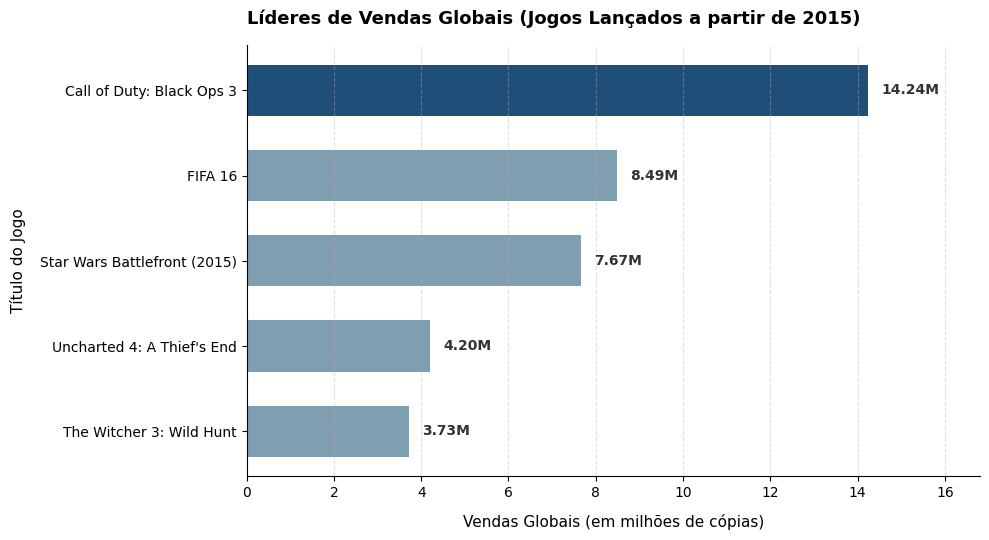

In [ ]:
#Atividade sala 2
# =====================================================================
# ETAPA 1: Importações (PEP 8) e Carga da Base Limpa
# =====================================================================
import matplotlib.pyplot as plt
import pandas as pd

# Lendo o CSV limpo gerado na atividade anterior (lembrando do separador ';')
arquivo_limpo = "jogos_sucesso_pos_2015.csv"
df_limpo = pd.read_csv(arquivo_limpo, sep=";")

print("Base limpa carregada com sucesso!\n")
print(df_limpo[["Name", "Year", "Genre", "Global_Sales"]], "\n")


# =====================================================================
# ETAPAS 2 e 3: Pergunta de Negócio, Gráfico e Profissionalização
# Pergunta: Quais jogos lideraram as vendas globais (em milhões) pós-2015?
# =====================================================================
# Ordena do menor para o maior para que o líder fique no topo do gráfico horizontal
df_ordenado = df_limpo.sort_values(by="Global_Sales", ascending=True)

# Define uma paleta de cores destacando o líder de vendas em azul-escuro
# e os demais em azul-acinzentado suave para facilitar o foco visual
cores = [
    "#1f4e78" if jogo == df_ordenado["Name"].iloc[-1] else "#7f9eb2"
    for jogo in df_ordenado["Name"]
]

plt.figure(figsize=(10, 5.5))

barras = plt.barh(
    df_ordenado["Name"],
    df_ordenado["Global_Sales"],
    color=cores,
    edgecolor="none",
    height=0.6,
)

# Adiciona os valores exatos na ponta de cada barra (rótulo de dados)
for barra in barras:
    largura = barra.get_width()
    plt.text(
        largura + 0.3,
        barra.get_y() + barra.get_height() / 2,
        f"{largura:.2f}M",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#333333",
    )

# Profissionalização: Título, Subtítulo, Eixos e Limpeza de Bordas
plt.title(
    "Líderes de Vendas Globais (Jogos Lançados a partir de 2015)",
    fontsize=13,
    fontweight="bold",
    pad=15,
    loc="left",
)
plt.xlabel("Vendas Globais (em milhões de cópias)", fontsize=11, labelpad=10)
plt.ylabel("Título do Jogo", fontsize=11, labelpad=10)

# Dá uma margem extra à direita para o texto "14.24M" não encostar na borda
plt.xlim(0, df_ordenado["Global_Sales"].max() * 1.18)

# Remove as bordas superior e direita (regra de ouro de design limpo)
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Grade vertical sutil apenas para guiar o olhar
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()